# First empirical study: SHFE copper covariance and risk

**Question.** Can a small transport-SPDE model, calibrated on historical settlement curves, give useful next-session outright and calendar-spread risk estimates?

This notebook explains an actual historical experiment, with 2022 initial history, 2023 validation and 2024–2025 rolling-origin evaluation. It reads committed **aggregate evidence**; the exchange archives, daily reconstructed curves and individual P&Ls remain local. It does not require a market-data download to read or rerun the presentation.

This is a first empirical baseline. Its effective source covariance is conditional on a finite curve representation, smoothing, a local covariance assumption and zero additional drift. It is not a demonstration of physical noise recovery, infinite-dimensional consistency or profitable trading.

## Main result of this first run

The three-mode local SPDE calibration **underpredicts spread and butterfly risk**. Over 484 subsequent test origins, realized/predicted variance is **1.186** for an outright, **2.279** for the spread and **6.933** for the butterfly. Direct covariance has lower paired QLIKE scores; the local SPDE method has no advantage under the primary QLIKE criterion.

This is a useful negative result for model development. Numerical convergence is verified; good optimizer behavior and a visually smooth price curve do not ensure adequate risk forecasts. The remaining cells show the evidence and separate reconstruction, calendar-clock and estimation issues. See [the findings note](../docs/shfe-findings.md).

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_study import render_empirical_figures
from spde_covariance.laguerre import LaguerreTransport

root = Path("../experiments/results/shfe-cu")
checks = json.loads((root / "evidence-sha256.json").read_text())
for name, digest in checks.items():
    assert hashlib.sha256((root / name).read_bytes()).hexdigest() == digest, name
s = json.loads((root / "summary.json").read_text())
manifest = json.loads((root / "manifest.json").read_text())
assert s["selection"]["selection_last_outcome"] <= "2023-12-31"
assert manifest["git_dirty"] is False
print("Numerical source revision:", manifest["git_revision"])
print("Test period:", *s["test_period"], "| origins:", s["test_origin_count"])
print("Evidence hashes verified.")

Numerical source revision: d284718c0e465d39886500ab2d85904183266747
Test period: 2024-01-02 2025-12-30 | origins: 484
Evidence hashes verified.


## 1. What data enter the study?

The official SHFE annual futures archives contain monthly XLS/XLSX workbooks. The parser selects actual `cuYYMM` contracts, checks duplicates and dates, and expands merged **contract labels** only inside declared spreadsheet merge ranges. It never fills prices, rolls contracts or substitutes closing prices for settlement prices.

Quotes are CNY per tonne; a copper contract represents **five tonnes**. The model uses the 15th of the contract month as its maturity coordinate. This is a convention known from the ID, **not** an inferred holiday-adjusted expiry or delivery-average pricing rule. Daily curves use positive settlement, volume and open interest at 30–365 days of maturity.

The annual archives are retrospective versions. The session calendar is treated as known, and forecasts are issued after that day's settlements are available; original release vintages have not been reconstructed.

In [2]:
print("Curve sessions:", s["reconstruction"]["sessions"])
print("Available curve reconstructions:", s["reconstruction"]["available_sessions"])
print("Nodes per reconstruction:", s["reconstruction"]["node_count_range"])
for a in s["data_audit"]["archives"]:
    print(a["filename"], "|", a["bytes"], "bytes | SHA256", a["sha256"][:16] + "…")
counts = {}
for table in s["data_audit"]["tables"]:
    for key, value in table["counts"].items():
        counts[key] = counts.get(key, 0) + value
print("Copper rows:", counts.get("copper_rows"))
print("Zero volume / zero OI:", counts.get("zero_volume", 0), counts.get("zero_open_interest", 0))
print("No price histories are stored in this notebook.")

Curve sessions: 969
Available curve reconstructions: 969
Nodes per reconstruction: [9, 12]
shfe-futures-2022.zip | 18790402 bytes | SHA256 38be8b5ff728a6aa…
shfe-futures-2023.zip | 24187534 bytes | SHA256 605e119b8f6e7cd7…
shfe-futures-2024.zip | 35087891 bytes | SHA256 68505aefe460ffa3…
shfe-futures-2025.zip | 76397695 bytes | SHA256 fe0122e1ff0e072f…
Copper rows: 11628
Zero volume / zero OI: 10 2
No price histories are stored in this notebook.


## 2. From a curve to a source covariance

Represent the curve as $f_t(x)=E(x)a_t$ in a three-dimensional, exactly shift-invariant integrated Laguerre basis. Its first function is constant. Each date's coefficients are reconstructed independently from that date's strip; a small shape penalty leaves the level unpenalized.

The declared local dynamics are

$$ da_t=Aa_t\,dt+b\,dt+L\,dW_t,\qquad C=LL^\top. $$

The study sets $b=0$. With $M_\Delta=e^{\Delta A}$, transport-adjusted coefficient changes satisfy the model relation

$$ r_i=\widehat a_i-M_{\Delta_i}\widehat a_{i-1},\qquad
\operatorname{Cov}(r_i)=K_{\Delta_i}(C)
=\int_0^{\Delta_i}M_uCM_u^\top\,du. $$

Normalized innovations have covariance $V_\Delta(C)=K_\Delta(C)/\Delta$. Every ACT/365.25 interval retains its **own** map. Unequal calendar intervals are not silently treated as a common $V$.

Here $C$ is the fitted, model-dependent source covariance; $V_\Delta$ is the normalized innovation covariance; $K_\Delta$ is the unnormalized change covariance. A loading $L$ is nonunique. Reconstructed states contain model and measurement errors: none of these quantities is asserted to be the market's true latent operator.

In [3]:
# A numerical identity independent of the market data:
model = LaguerreTransport(3)
x_end = np.array([0.2, 0.5, 0.75])
delta = 3 / 365.25
roll_error = np.max(
    np.abs(model.evaluate(x_end) @ model.matrix(delta) - model.evaluate(x_end + delta))
)
assert roll_error < 1e-12
print("Same-contract transport identity error:", f"{roll_error:.2e}")
print("Curve reconstruction RMSE quantiles, CNY/tonne [min,Q1,median,Q3,max]:")
print(np.round(s["reconstruction"]["rmse_quantiles_cny_per_tonne"], 2))
print(
    "Reconstruction condition number [min,median,max]:",
    np.round(s["reconstruction"]["design_condition_quantiles"], 1),
)

Same-contract transport identity error: 5.55e-17
Curve reconstruction RMSE quantiles, CNY/tonne [min,Q1,median,Q3,max]:
[  9.69  34.06  48.58  72.69 968.45]
Reconstruction condition number [min,median,max]: [58.4 70.  85.7]


The PSD source fit minimizes a ridge-regularized moment objective

$$ \frac{1}{2m}\sum_{i\in\mathcal W_t}
\left\|V_{\Delta_i}(C)-\frac{r_ir_i^\top}{\Delta_i}\right\|_F^2
+\frac{\lambda}{2}\|C\|_F^2,
\qquad C\succeq0,\quad\operatorname{tr}(C)\le R_t. $$

Relative ridge is $10^{-3}$ times the interval-map Gram norm. The explicit trace cap is 100 times an in-window residual trace proxy adjusted for transport trace gain. Solver scaling and certificates are recorded. These bound numerical error to this optimizer; they do not bound statistical or representation error.

Numerical diagnostics:
  relative_covariance_error_bound = 8.056297356695254e-06
  objective_gap_bound_scaled = 3.1999106240154385e-11
  maximum_relative_risk_bound = 0.00647020476009218
  available = True
  all_converged = True
  minimum_source_eigenvalue = 4116288.714366688
  maximum_relative_trace_violation = 0.0


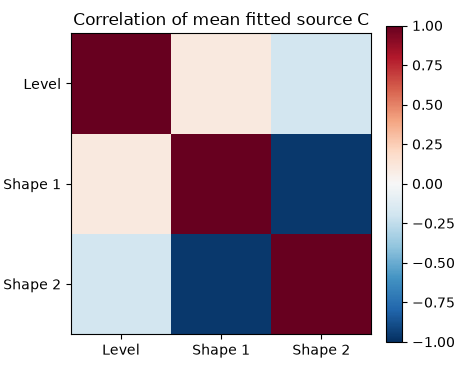

In [4]:
print("Numerical diagnostics:")
for key, value in s["numerical_diagnostics"].items():
    print(" ", key, "=", value)
C = np.array(s["mean_source_covariance"])
scale = np.sqrt(np.diag(C))
correlation = C / np.outer(scale, scale)
fig, ax = plt.subplots(figsize=(4.6, 3.7), layout="constrained")
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(3), ["Level", "Shape 1", "Shape 2"])
ax.set_yticks(range(3), ["Level", "Shape 1", "Shape 2"])
ax.set_title("Correlation of mean fitted source C")
fig.colorbar(im, ax=ax)
plt.show()

## 3. What is forecast, and what is scored?

At each origin, choose distinct contracts nearest 90, 180 and 270 days using origin information only. Hold the **same IDs** to the next exchange session. The portfolios are one near contract, a near-minus-middle spread, and a near-minus-two-middle-plus-far butterfly.

For positions $q$, the forecast variance in CNY² is

$$\widehat v=25\,q^\top E(x_{\rm next})K_{\Delta_{\rm next}}(\widehat C_t)E(x_{\rm next})^\top q.$$

The factor 25 is the square of the five-tonne multiplier. This is one subsequent interval, not an annual or accumulated-return risk. The same-contract identity above cancels deterministic roll-down. Mean prices are anchored to actual origin settlements, so reconstruction errors do not create artificial mean reversion.

Observed squared P&L $z$ scores the conditional **second moment**. Under the declared zero additional mean it approximates the variance target. QLIKE is $\log v+z/v$, minimized in conditional expectation at $v=\mathbb E[z\mid\mathcal F_t]$. It is used as a proxy loss, without a Gaussian-density claim. The fixed 25 CNY² floor and floor-hit counts are recorded.

## 4. Chronology and fair comparisons

- **2022:** initial history and a static SPDE fit.
- **2023:** choose a trailing count from 63, 126 and 252 intervals, using subsequent validation observations only. SPDE, direct and shrinkage methods select their own windows; exact ties prefer the longer window.
- **2024–2025:** freeze those choices and refit using observations through each origin. A later origin may use earlier test observations; no origin uses its own future outcome.

Direct covariance and fixed 10% diagonal shrinkage use histories of the currently held contracts. Each exposure requires at least 20 adjacent, jointly observed changes for its own support. Baselines are issued independently of SPDE solver success. Paired comparisons use identical future P&Ls and common available dates.

Fixed-126 and static SPDE fits examine adaptation. An $A=0$ ablation uses ordinary coefficient increments throughout. Dimensions two and four, and stronger cross-sectional smoothing, are declared sensitivities rather than test-tuned winners.

In [5]:
print("SPDE validation:", json.dumps(s["selection"], indent=2))
print("Baseline validation:", json.dumps(s["baseline_selection"], indent=2))
assert all(v <= 252 for v in s["baseline_selection"]["selected_windows"].values())
print("Unavailable forecast attempts:", s["failure_count"], s["failure_reasons"])

SPDE validation: {
  "selected_window": 252,
  "mean_qlike": {
    "63": 31.277732651191446,
    "126": 32.31126043076279,
    "252": 21.814553028419674
  },
  "origins": 231,
  "selection_last_outcome": "2023-12-29",
  "unavailable_candidate_fits": 0
}
Baseline validation: {
  "selected_windows": {
    "direct": 63,
    "shrinkage": 63
  },
  "mean_qlike": {
    "direct": {
      "63": 15.901422713016252,
      "126": 16.03070566945036,
      "252": 16.043101243025923
    },
    "shrinkage": {
      "63": 15.95515266243326,
      "126": 15.991665223529976,
      "252": 16.003805596754567
    }
  },
  "origins": 231,
  "selection_last_outcome": "2023-12-29"
}
Unavailable forecast attempts: 0 []


## 5. Historical risk calibration

A realized-to-predicted variance ratio near one indicates aggregate second-moment calibration. A value above one indicates underprediction in this sample. The ratio is **not** an operator-error estimate, a tail-coverage guarantee or a profit measure. Method counts matter; their unconditional averages can use different dates.

Exposure                   Method                N  Real/pred    Pred RMS    Real RMS
outright_3m                direct              484      1.096      3331.2      3487.1
outright_3m                shrinkage           484      1.096      3331.2      3487.1
outright_3m                spde_dim2           484      1.187      3200.6      3487.1
outright_3m                spde_dim4           484      1.183      3205.8      3487.1
outright_3m                spde_fixed126       484      1.165      3230.4      3487.1
outright_3m                spde_local          484      1.186      3202.4      3487.1
outright_3m                spde_smoother       484      1.187      3201.1      3487.1
outright_3m                spde_static         484      0.935      3605.5      3487.1
outright_3m                unadjusted          484      1.186      3202.4      3487.1
spread_3m_6m               direct              484      0.455       747.8       504.3
spread_3m_6m               shrinkage           484    

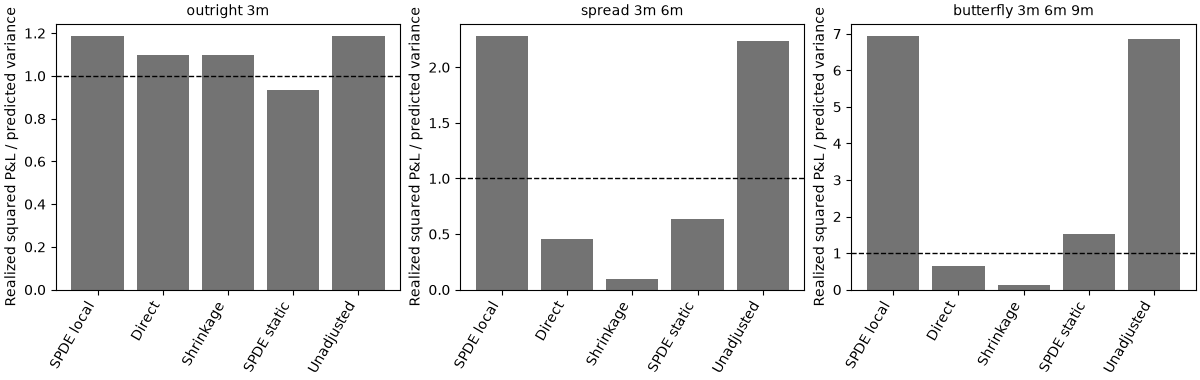

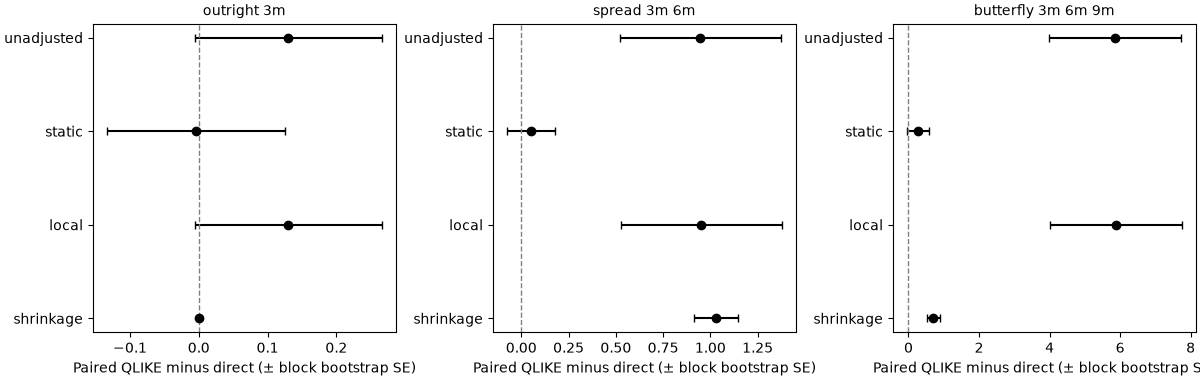

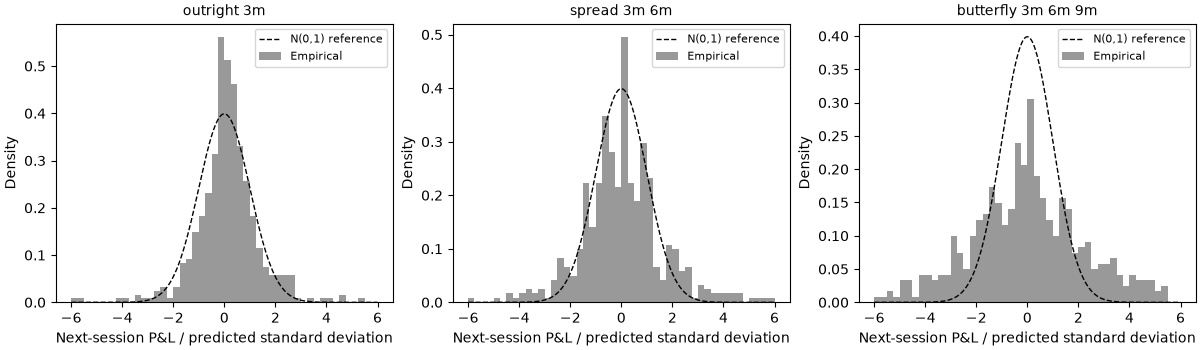

In [6]:
print(f"{'Exposure':26} {'Method':17} {'N':>5} {'Real/pred':>10} {'Pred RMS':>11} {'Real RMS':>11}")
for r in s["risk_summary"]:
    if r["year"] == "all":
        print(
            f"{r['exposure']:26} {r['method']:17} {r['count']:5d} {r['risk_ratio']:10.3f} "
            f"{r['predicted_rms_cny']:11.1f} {r['realized_rms_cny']:11.1f}"
        )
figures = render_empirical_figures(s)
plt.show()

The first figure compares aggregate risk calibration. The second shows the primary **paired** QLIKE differences against direct covariance; negative values favor the listed method. Error bars are moving-block bootstrap standard errors, with 20 scored origins per block. Dates are not independent simulation replications. All dimension and smoothing sensitivities remain in the printed tables and JSON. The final histograms compare standardized P&L with a standard-normal reference as a diagnostic, without asserting Gaussian tails.

In [7]:
print(f"{'Exposure':26} {'Method minus direct':20} {'N':>5} {'Difference':>12} {'Block SE':>12}")
for r in s["paired_qlike"]:
    if r["year"] == "all":
        print(
            f"{r['exposure']:26} {r['method']:20} {r['count']:5d} {r['mean']:12.4f} "
            f"{r['bootstrap_standard_error']:12.4f}"
        )
print("Secondary quadratic proxy score differences, SPDE local minus direct (CNY^4):")
for exposure in ("outright_3m", "spread_3m_6m", "butterfly_3m_6m_9m"):
    rows = {
        r["method"]: r
        for r in s["risk_summary"]
        if r["year"] == "all" and r["exposure"] == exposure
    }
    diff = rows["spde_local"]["mean_quadratic_score"] - rows["direct"]["mean_quadratic_score"]
    print(exposure, f"{diff:.3e}")
print(
    "Negative values favor SPDE on this secondary loss. Rankings are loss-specific; QLIKE remains the frozen primary criterion."
)

Exposure                   Method minus direct      N   Difference     Block SE
outright_3m                shrinkage              484      -0.0000       0.0000
outright_3m                spde_dim2              484       0.1291       0.1357
outright_3m                spde_dim4              484       0.1294       0.1359
outright_3m                spde_fixed126          484       0.1110       0.0970
outright_3m                spde_local             484       0.1303       0.1360
outright_3m                spde_smoother          484       0.1301       0.1360
outright_3m                spde_static            484      -0.0045       0.1294
outright_3m                unadjusted             484       0.1304       0.1361
spread_3m_6m               shrinkage              484       1.0296       0.1160
spread_3m_6m               spde_dim2              484       1.1906       0.4946
spread_3m_6m               spde_dim4              484       0.7087       0.3696
spread_3m_6m               spde_fixed126

## A diagnostic of reconstruction risk

For each actual held contract, exact transport gives a decomposition of the **subsequently realized** change:

$$\Delta p = E(x_{\rm next})r + \Delta e,$$

where $e$ is settlement minus the reconstructed curve. For portfolio P&L $Y=S+U$, retain all terms:

$$\mathbb E[Y^2]=\mathbb E[S^2]+\mathbb E[U^2]+2\mathbb E[SU].$$

The following sample second-moment shares are diagnostic; they do not use centered variances. Residual and fitted-curve changes need not be independent, so the cross share can have either sign. The decomposition uses future observations **only to explain realized outcomes**. It does not feed them back into calibration, window selection or issued forecasts.

In [8]:
decomposition = s["reconstruction_risk_decomposition"]
print(f"{'Exposure':26} {'N':>5} {'Curve share':>12} {'Residual':>12} {'Cross':>12}")
for r in decomposition["exposures"]:
    print(
        f"{r['exposure']:26} {r['count']:5d} {r['modeled_share']:12.3f} "
        f"{r['residual_share']:12.3f} {r['cross_share']:12.3f}"
    )
    assert abs(r["modeled_share"] + r["residual_share"] + r["cross_share"] - 1) < 1e-10
print("This is a model diagnostic, not a fresh-noise variance correction.")
print(
    "The fitted curve captures 99.1% of outright, 38.3% of spread and 11.4% of butterfly sample second moments."
)

Exposure                       N  Curve share     Residual        Cross
outright_3m                  484        0.991        0.002        0.007
spread_3m_6m                 484        0.383        0.619       -0.002
butterfly_3m_6m_9m           484        0.114        0.778        0.108
This is a model diagnostic, not a fresh-noise variance correction.
The fitted curve captures 99.1% of outright, 38.3% of spread and 11.4% of butterfly sample second moments.


## 6. A useful model check: calendar time

A constant source per calendar year allocates more variance to a three-day weekend than a one-day interval. Whether the data support this is an empirical question, not a semigroup identity. The following ratios separate one-day, weekend-length and longer holiday gaps. Differences motivate later business-time or event-time extensions.

In [9]:
print(f"{'Exposure':26} {'Calendar gap':14} {'N':>5} {'Real/pred':>12}")
for r in s["calendar_interval_diagnostics"]:
    print(f"{r['exposure']:26} {r['calendar_interval']:14} {r['count']:5d} {r['risk_ratio']:12.3f}")
print("Yearly SPDE local / direct QLIKE:")
for r in s["risk_summary"]:
    if r["year"] != "all" and r["method"] in ("spde_local", "direct"):
        print(r["year"], r["exposure"], r["method"], round(r["qlike"], 3))

Exposure                   Calendar gap       N    Real/pred
outright_3m                1 day            380        1.447
outright_3m                2–3 days          93        0.630
outright_3m                4+ days           11        1.989
spread_3m_6m               1 day            380        3.426
spread_3m_6m               2–3 days          93        1.267
spread_3m_6m               4+ days           11        0.332
butterfly_3m_6m_9m         1 day            380       10.614
butterfly_3m_6m_9m         2–3 days          93        3.104
butterfly_3m_6m_9m         4+ days           11        2.688
Yearly SPDE local / direct QLIKE:
2024 outright_3m direct 17.28
2024 outright_3m spde_local 17.446
2025 outright_3m direct 17.252
2025 outright_3m spde_local 17.347
2024 spread_3m_6m direct 13.462
2024 spread_3m_6m spde_local 14.067
2025 spread_3m_6m direct 13.754
2025 spread_3m_6m spde_local 15.052
2024 butterfly_3m_6m_9m direct 14.826
2024 butterfly_3m_6m_9m spde_local 18.888
2025 butt

## 7. What this establishes—and what remains open

The experiment establishes a reproducible connection from actual settlement strips to a declared finite transport model, an interval-aware PSD covariance calibration, and subsequent same-contract portfolio-risk evaluation. It supplies measured comparisons and visible failure diagnostics; it does not require the SPDE method to beat direct covariance.

The main uncertainties remain:

1. **Reconstruction and identification:** the source depends on basis, smoothing and the observed maturity strip. Curve-fit residuals are not known fresh innovation noise.
2. **Time and dynamics:** weekend/holiday scaling, time variation, heavy tails and nonzero conditional means can violate the local model.
3. **Data vintage and contracts:** revisions, publication timing, actual delivery maps and wider maturity coverage require separate audits.
4. **Scope:** one market and two test years do not establish a universal result. No execution, transaction-cost, VaR or profitability backtest is claimed.

The project now has an empirical baseline to improve. The next step is to prioritize the largest measured risk misspecification before adding model complexity.

## Reproduction

The public notebook runs from committed aggregate JSON and verifies its hashes. Full local reproduction:

```sh
uv sync --locked --extra empirical --extra reference
uv run python scripts/download_shfe.py --years 2022 2023 2024 2025 --cache-dir data/local/shfe
uv run spde-covariance empirical-shfe experiments/configs/shfe-cu.toml \
  --data data/local/shfe --output data/local/shfe/runs/reproduction
uv run python scripts/check_notebook.py notebooks/shfe_empirical.ipynb
```

See [the protocol](../docs/shfe-empirical.md), [the aggregate report](../experiments/results/shfe-cu/report.md) and its source manifest. Raw archives, clean panels and forecast-level outcomes remain Git-ignored. The MIT license covers our code and does not relicense SHFE market data.